# Latent Dirichlet Allocation (LDA)

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/02-06-Latent-Dirichlet-Allocation.ipynb)

In the chapter on Latent Semantic Analysis (LSA) we found "topics" as directions obtained from the singular value decomposition of a TF-IDF matrix. These directions are hard to interpret: their entries can be negative and they are not probabilities.

Latent Dirichlet Allocation [@BLEI2003LatentDirichletAllocation] is a *probabilistic* topic model. It describes

- each **topic** as a probability distribution over the words of the vocabulary, and
- each **document** as a mixture of topics, i.e. a probability distribution over the topics.

The name comes from the **Dirichlet distribution**, a distribution over probability vectors that LDA uses to model both of these. We first study the Dirichlet distribution, then the LDA model, then fit LDA on a small simulated corpus by hand and finally on the Reuters news articles from the LSA chapter.

## Notation and assumptions

| Symbol | Meaning |
|--------|---------|
| $V$ | Number of distinct words in the vocabulary |
| $K$ | Number of topics (chosen by us, fixed in advance) |
| $D$ | Number of documents in the corpus |
| $N_d$ | Number of words (tokens) in document $d$ |
| $w_{d,n}$ | The $n$-th word of document $d$ (an index in $1, \dots, V$) |

**Assumptions.**

1. **Bag of words:** the order of the words within a document does not matter, only their counts (as in the BoW and TF-IDF chapters).
2. The order of the documents in the corpus does not matter.
3. The number of topics $K$ is known.

In [1]:
import math
import re
from itertools import permutations

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

## The Dirichlet distribution

### Probability vectors and the simplex

A vector $\theta = (\theta_1, \dots, \theta_K)$ is a **probability vector** if

$$
\theta_k \ge 0 \text{ for all } k \quad \text{and} \quad \sum_{k=1}^{K} \theta_k = 1.
$$

The set of all such vectors is called the **probability simplex** $\Delta^{K-1}$. In LDA, the topic proportions of a document and the word probabilities of a topic are both probability vectors. For example, $\theta = (0.7, 0.2, 0.1)$ could mean "70% of this document is about topic 1, 20% about topic 2, 10% about topic 3".

For $K = 3$ the simplex is a triangle: each corner is a vector with a single 1 (e.g. $(1, 0, 0)$, "only topic 1"), and the centre is $(1/3, 1/3, 1/3)$.

### Definition

**Definition.** Let $\alpha = (\alpha_1, \dots, \alpha_K)$ with all $\alpha_k > 0$. A random probability vector $\theta$ follows a **Dirichlet distribution** $\theta \sim \text{Dir}(\alpha)$ if its density on the simplex is

$$
p(\theta \mid \alpha) = \frac{\Gamma\left(\sum_{k=1}^{K} \alpha_k\right)}{\prod_{k=1}^{K} \Gamma(\alpha_k)} \prod_{k=1}^{K} \theta_k^{\alpha_k - 1}.
$$

| Symbol | Meaning |
|--------|---------|
| $\theta_k$ | The $k$-th component of the random probability vector |
| $\alpha_k$ | Concentration parameter for component $k$ |
| $\Gamma(\cdot)$ | The gamma function, which extends the factorial: $\Gamma(m) = (m-1)!$ for positive integers $m$ |
| Fraction in front | Normalising constant that makes the density integrate to 1 over the simplex |

Most of the time LDA uses a **symmetric** Dirichlet where all $\alpha_k$ equal the same number $\alpha$. We then write $\text{Dir}(\alpha)$ with a single number.

**Mean** (stated without proof):

$$
E[\theta_k] = \frac{\alpha_k}{\sum_{j=1}^{K} \alpha_j}.
$$

For the symmetric Dirichlet the mean is $(1/K, \dots, 1/K)$, whatever the value of $\alpha$. What $\alpha$ controls is how far a typical sample is from this mean:

- $\alpha < 1$: samples are **sparse**, most of the mass sits on one or two components (near the corners of the triangle). For documents: "each document is about few topics".
- $\alpha = 1$: all points of the simplex are equally likely (uniform distribution).
- $\alpha > 1$: samples are close to the centre, all components are similar ("every document mixes all topics evenly").

We first evaluate the density formula by hand for $K = 3$, $\alpha = (2, 3, 4)$ at the point $\theta = (0.2, 0.3, 0.5)$ and compare with `scipy`.

In [22]:
alpha_example = np.array([2.0, 3.0, 4.0])
theta_point = np.array([0.2, 0.3, 0.5])

normalising_constant = math.gamma(alpha_example.sum()) / np.prod([math.gamma(a) for a in alpha_example])
density_by_hand = normalising_constant * np.prod(theta_point ** (alpha_example - 1))

print("Normalising constant:", normalising_constant)
print("Density by hand:     ", round(density_by_hand, 4))
print("Density from scipy:  ", round(stats.dirichlet.pdf(theta_point, alpha_example), 4))

Normalising constant: 3360.0
Density by hand:      7.56
Density from scipy:   7.56


### Sampling from the Dirichlet distribution

`numpy` can draw samples with `rng.dirichlet(alpha, size)`. Every sample is a probability vector, so each row below sums to 1.

In [23]:
rng = np.random.default_rng(42)

samples_table = pd.DataFrame(
    rng.dirichlet([1.0, 1.0, 1.0], size=5),
    columns=["theta_1", "theta_2", "theta_3"],
)
samples_table["sum"] = samples_table.sum(axis=1)
samples_table.round(3)

,theta_1,theta_2,theta_3,sum
0,0.337,0.328,0.335,1.0
1,0.154,0.048,0.799,1.0
2,0.306,0.677,0.017,1.0
3,0.474,0.032,0.494,1.0
4,0.517,0.115,0.368,1.0


To see the effect of $\alpha$ we draw 1000 samples for $\alpha \in \{0.1, 1, 10\}$ and plot them on the triangle. A probability vector $(\theta_1, \theta_2, \theta_3)$ is drawn at the point

$$
x = \theta_2 + \tfrac{1}{2}\theta_3, \qquad y = \tfrac{\sqrt{3}}{2}\, \theta_3,
$$

so that $(1, 0, 0)$, $(0, 1, 0)$ and $(0, 0, 1)$ land on the three corners of an equilateral triangle.

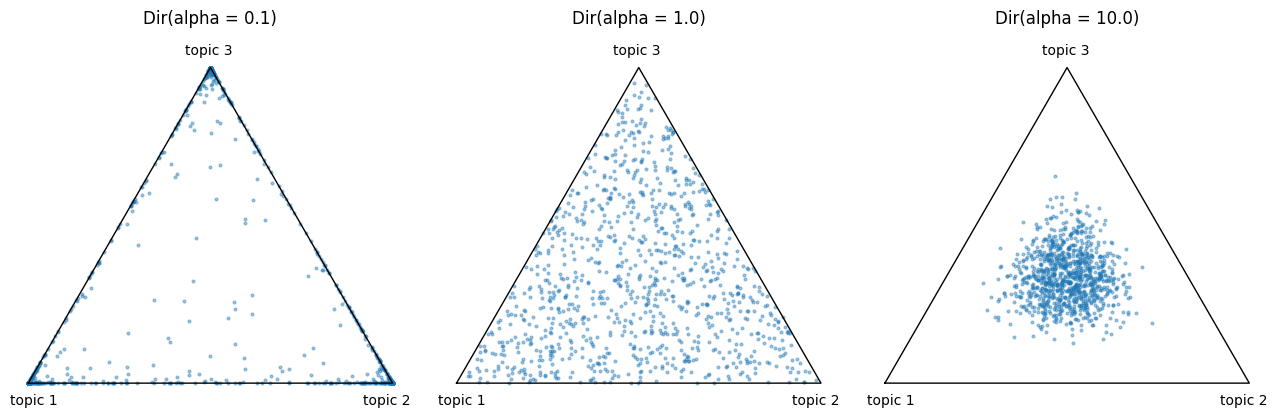

In [24]:
def to_triangle(theta):
    # Map 3-component probability vectors to 2-D points inside an equilateral triangle.
    x = theta[:, 1] + 0.5 * theta[:, 2]
    y = np.sqrt(3) / 2 * theta[:, 2]
    return x, y


corners = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2], [0, 0]])
rng = np.random.default_rng(1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, alpha_value in zip(axes, [0.1, 1.0, 10.0]):
    theta_samples = rng.dirichlet([alpha_value] * 3, size=1000)
    x, y = to_triangle(theta_samples)
    ax.plot(corners[:, 0], corners[:, 1], color="black", linewidth=1)
    ax.scatter(x, y, s=4, alpha=0.4)
    ax.text(-0.05, -0.06, "topic 1")
    ax.text(0.92, -0.06, "topic 2")
    ax.text(0.43, 0.9, "topic 3")
    ax.set_title(f"Dir(alpha = {alpha_value})", pad=20)
    ax.set_aspect("equal")
    ax.axis("off")
plt.tight_layout()
plt.show()

With $\alpha = 0.1$ almost all samples sit at the corners or on the edges (one or two topics dominate), with $\alpha = 1$ they cover the triangle evenly, and with $\alpha = 10$ they cluster around the centre.

**Conjugacy (stated without proof).** If $\theta \sim \text{Dir}(\alpha)$ and we then observe counts $n_1, \dots, n_K$ of categories drawn with probabilities $\theta$, the posterior distribution of $\theta$ is again Dirichlet:

$$
\theta \mid n_1, \dots, n_K \sim \text{Dir}(\alpha_1 + n_1, \dots, \alpha_K + n_K).
$$

So $\alpha_k$ acts like a number of "pseudo-counts" added to the observed counts. This property makes the inference algorithm below simple.

## The LDA model

LDA describes how a corpus *could have been generated*. The parameters are the number of topics $K$ and two Dirichlet concentrations: $\alpha$ for the topic proportions of documents and $\eta$ for the word probabilities of topics.

**Generative process.**

1. For each topic $k = 1, \dots, K$: draw its word distribution $\beta_k \sim \text{Dir}(\eta)$, a probability vector of length $V$.
2. For each document $d = 1, \dots, D$:
   1. draw its topic proportions $\theta_d \sim \text{Dir}(\alpha)$, a probability vector of length $K$;
   2. for each word position $n = 1, \dots, N_d$:
      - draw a topic $z_{d,n} \sim \text{Categorical}(\theta_d)$,
      - draw the word $w_{d,n} \sim \text{Categorical}(\beta_{z_{d,n}})$.

| Symbol | Size | Meaning | Observed? |
|--------|------|---------|-----------|
| $\beta_k$ | $V$ | Probability of each word in topic $k$ | no (latent) |
| $\theta_d$ | $K$ | Topic proportions of document $d$ | no (latent) |
| $z_{d,n}$ | 1 | Topic that produced the $n$-th word of document $d$ | no (latent) |
| $w_{d,n}$ | 1 | The $n$-th word of document $d$ | **yes** |
| $\alpha$, $\eta$ | 1 each | Dirichlet concentrations (hyperparameters) | chosen by us |

"Latent" means hidden: we only ever see the words. "Categorical$(p)$" draws one of several categories, category $j$ with probability $p_j$.

**Matrix view.** Collect the topic proportions as rows of the document-topic matrix $\Theta$ ($D \times K$) and the word distributions as rows of the topic-word matrix $B$ ($K \times V$). The probability that a word in document $d$ is word $v$ is

$$
P(w_{d,n} = v) = \sum_{k=1}^{K} \theta_{d,k}\, \beta_{k,v} = (\Theta B)_{d,v}.
$$

So the $D \times V$ matrix of word probabilities is factorised as $\Theta B$, similar to the low-rank factorisation in LSA, but here all entries are non-negative and every row is a probability vector.

## A toy example: generating a corpus

We follow the generative process with a vocabulary of $V = 8$ words and $K = 2$ topics. To be able to recognise the topics later, we fix the topic-word matrix $B$ by hand instead of drawing it from $\text{Dir}(\eta)$: topic 0 is about coffee, topic 1 about prices.

In [5]:
vocabulary = ["coffee", "beans", "harvest", "brazil", "prices", "inflation", "index", "rise"]
n_words = len(vocabulary)   # V
n_topics = 2                # K

true_topic_word = np.array([
    [0.30, 0.25, 0.20, 0.20, 0.02, 0.01, 0.01, 0.01],   # topic 0: coffee
    [0.01, 0.01, 0.01, 0.02, 0.30, 0.25, 0.20, 0.20],   # topic 1: prices
])
assert np.allclose(true_topic_word.sum(axis=1), 1)

pd.DataFrame(true_topic_word, index=["topic 0", "topic 1"], columns=vocabulary)

,coffee,beans,harvest,brazil,prices,inflation,index,rise
topic 0,0.30,0.25,0.20,0.20,0.02,0.01,0.01,0.01
topic 1,0.01,0.01,0.01,0.02,0.30,0.25,0.20,0.20


Next we generate $D = 10$ documents with $N_d = 30$ words each and $\alpha = 0.5$ (a value below 1, so most documents lean towards one topic).

In [6]:
n_documents = 10
words_per_document = 30
alpha = 0.5

rng = np.random.default_rng(7)

true_doc_topic = rng.dirichlet([alpha] * n_topics, size=n_documents)   # Theta, D x K

documents = []      # word indices w_{d,n}
assignments = []    # topic indices z_{d,n}
for d in range(n_documents):
    topics_of_words = rng.choice(n_topics, size=words_per_document, p=true_doc_topic[d])
    words = np.array([rng.choice(n_words, p=true_topic_word[k]) for k in topics_of_words])
    assignments.append(topics_of_words)
    documents.append(words)

pd.DataFrame(true_doc_topic, columns=["topic 0", "topic 1"]).round(3)

,topic 0,topic 1
0,0.338,0.662
1,1.000,0.000
2,0.908,0.092
3,0.137,0.863
4,0.930,0.070
5,0.119,0.881
6,0.877,0.123
7,1.000,0.000
8,0.016,0.984
9,0.634,0.366


Each row of $\Theta$ above is the (hidden) topic mixture of one document. Here are the first words of the first three documents together with the topics $z_{d,n}$ that generated them:

In [7]:
for d in range(3):
    print(f"Document {d}  (theta = {true_doc_topic[d].round(2)})")
    print("  words: ", " ".join(vocabulary[w] for w in documents[d][:12]), "...")
    print("  topics:", " ".join(str(k) for k in assignments[d][:12]), "...")

Document 0  (theta = [0.34 0.66])
  words:  rise inflation prices prices rise harvest prices brazil harvest inflation inflation inflation ...
  topics: 1 1 1 1 1 0 1 0 0 1 1 1 ...
Document 1  (theta = [1. 0.])
  words:  beans beans brazil harvest harvest beans brazil beans brazil coffee beans beans ...
  topics: 0 0 0 0 0 0 0 0 0 0 0 0 ...
Document 2  (theta = [0.91 0.09])
  words:  beans brazil inflation brazil harvest harvest coffee harvest coffee brazil prices brazil ...
  topics: 0 0 1 0 0 0 0 0 0 0 0 0 ...


An LDA fitting algorithm only sees the words, which (bag of words) we can summarise as a document-term count matrix:

In [8]:
toy_counts = np.zeros((n_documents, n_words), dtype=int)
for d, words in enumerate(documents):
    for w in words:
        toy_counts[d, w] += 1

pd.DataFrame(toy_counts, columns=vocabulary)

,coffee,beans,harvest,brazil,prices,inflation,index,rise
0,1,2,4,5,6,8,0,4
1,6,9,7,6,1,1,0,0
2,7,3,8,8,2,1,1,0
3,3,1,0,0,10,4,8,4
4,9,6,3,7,2,0,1,2
5,0,0,1,2,9,6,6,6
6,3,8,10,6,1,1,0,1
7,7,12,6,5,0,0,0,0
8,0,1,1,2,9,4,6,7
9,6,2,5,4,4,3,4,2


## Inference: from words back to topics

Fitting LDA means going backwards: given only the words $w$, find likely values of the topic assignments $z$, the document-topic matrix $\Theta$ and the topic-word matrix $B$. The exact posterior distribution $p(\Theta, B, z \mid w)$ cannot be computed in closed form, so approximate algorithms are used. Two common ones are

- **collapsed Gibbs sampling** [@GRIFFITHS2004FindingScientificTopics], which we implement below, and
- **variational Bayes** [@BLEI2003LatentDirichletAllocation], which is what scikit-learn uses.

Both fit the same model; they differ in how they approximate the posterior.

### Collapsed Gibbs sampling

The idea is to start with random topic assignments $z_{d,n}$ and then repeatedly re-draw the topic of one word at a time, given the topics of all other words. Thanks to the Dirichlet conjugacy, $\Theta$ and $B$ can be integrated out ("collapsed"), and only the following counts are needed:

| Count | Meaning |
|-------|---------|
| $n_{d,k}$ | Number of words in document $d$ currently assigned to topic $k$ |
| $n_{k,v}$ | Number of times word $v$ is currently assigned to topic $k$ (over all documents) |
| $n_{k}$ | Total number of words currently assigned to topic $k$ |

A superscript $^{-}$ means that the word we are about to re-draw is removed from the counts.

**Update rule** (result from [@GRIFFITHS2004FindingScientificTopics]; derivation omitted). For word $n$ in document $d$ with $w_{d,n} = v$:

$$
P(z_{d,n} = k \mid \text{all other } z, w) \propto \underbrace{\left(n^{-}_{d,k} + \alpha\right)}_{\text{how much document } d \text{ uses topic } k} \times \underbrace{\frac{n^{-}_{k,v} + \eta}{n^{-}_{k} + V\eta}}_{\text{how much topic } k \text{ uses word } v}.
$$

Both factors are "counts plus pseudo-counts", exactly as in the conjugacy statement above. After enough sweeps over all words, the counts give the estimates

$$
\hat\theta_{d,k} = \frac{n_{d,k} + \alpha}{N_d + K\alpha}, \qquad \hat\beta_{k,v} = \frac{n_{k,v} + \eta}{n_k + V\eta}.
$$

In [9]:
def gibbs_lda(documents, n_topics, n_words, alpha, eta, n_sweeps, seed):
    rng = np.random.default_rng(seed)

    # Random initial topic for every word
    topics = [rng.integers(n_topics, size=len(words)) for words in documents]

    doc_topic_counts = np.zeros((len(documents), n_topics))
    topic_word_counts = np.zeros((n_topics, n_words))
    for d, words in enumerate(documents):
        for w, k in zip(words, topics[d]):
            doc_topic_counts[d, k] += 1
            topic_word_counts[k, w] += 1
    topic_totals = topic_word_counts.sum(axis=1)

    for sweep in range(n_sweeps):
        for d, words in enumerate(documents):
            for n, w in enumerate(words):
                # Remove the current word from the counts
                k = topics[d][n]
                doc_topic_counts[d, k] -= 1
                topic_word_counts[k, w] -= 1
                topic_totals[k] -= 1

                # Update rule: probability of each topic for this word
                weights = (doc_topic_counts[d] + alpha) * (topic_word_counts[:, w] + eta) / (topic_totals + n_words * eta)
                k = rng.choice(n_topics, p=weights / weights.sum())

                # Add the word back with its new topic
                topics[d][n] = k
                doc_topic_counts[d, k] += 1
                topic_word_counts[k, w] += 1
                topic_totals[k] += 1

    doc_lengths = doc_topic_counts.sum(axis=1, keepdims=True)
    doc_topic_estimate = (doc_topic_counts + alpha) / (doc_lengths + n_topics * alpha)
    topic_word_estimate = (topic_word_counts + eta) / (topic_totals[:, None] + n_words * eta)
    return doc_topic_estimate, topic_word_estimate

In [10]:
estimated_doc_topic, estimated_topic_word = gibbs_lda(
    documents, n_topics=2, n_words=n_words, alpha=0.5, eta=0.1, n_sweeps=300, seed=0
)

**Label switching.** The model does not know that we called the coffee topic "topic 0". The sampler may well find it as "topic 1". Before comparing, we therefore reorder the estimated topics so that they best match the true ones.

In [11]:
best_order = min(
    permutations(range(n_topics)),
    key=lambda order: np.abs(estimated_topic_word[list(order)] - true_topic_word).sum(),
)
estimated_topic_word = estimated_topic_word[list(best_order)]
estimated_doc_topic = estimated_doc_topic[:, list(best_order)]
print("Estimated topics reordered as", best_order)

Estimated topics reordered as (1, 0)


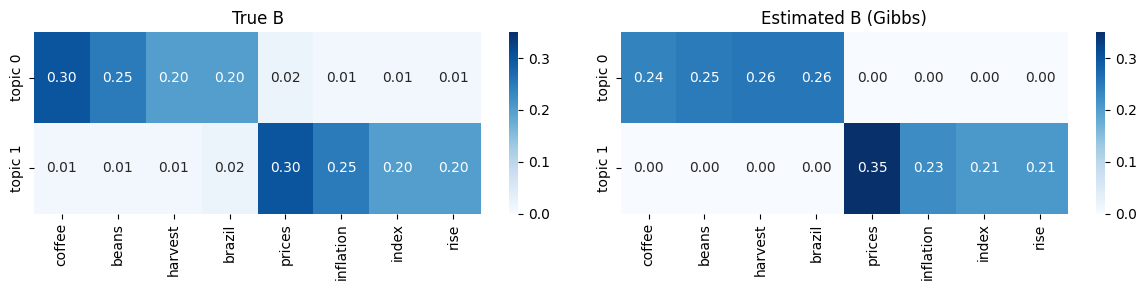

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, matrix, title in zip(axes, [true_topic_word, estimated_topic_word], ["True B", "Estimated B (Gibbs)"]):
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.35,
                xticklabels=vocabulary, yticklabels=["topic 0", "topic 1"], ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [13]:
pd.DataFrame(
    {
        "true theta (topic 0)": true_doc_topic[:, 0],
        "estimated theta (topic 0)": estimated_doc_topic[:, 0],
    }
).round(3)

,true theta (topic 0),estimated theta (topic 0)
0,0.338,0.403
1,1.000,0.919
2,0.908,0.855
3,0.137,0.145
4,0.930,0.823
5,0.119,0.113
6,0.877,0.887
7,1.000,0.984
8,0.016,0.145
9,0.634,0.565


From the words alone, the sampler recovers both the two topics and how much of each document is about coffee. The estimates are not exact: each document has only 30 words, and the prior pseudo-counts $\alpha$ pull the estimated proportions slightly towards $1/2$.

## LDA on Reuters news articles

We now use the same Reuters articles as in the LSA chapter: news from the categories `gas`, `cpi` (consumer price index) and `coffee`. We ask LDA for $K = 3$ topics without telling it the categories and check whether the topics it finds correspond to them.

In [14]:
nltk.download("reuters", quiet=True)
from nltk.corpus import reuters

categories = ["gas", "cpi", "coffee"]
texts = []
labels = []
for category in categories:
    for fileid in reuters.fileids(category):
        texts.append(reuters.raw(fileid))
        labels.append(category)

# Numbers are very frequent in these articles and are not informative about the topic
texts = [re.sub(r"\d+", "", text) for text in texts]

pd.Series(labels).value_counts()

coffee    139
cpi        97
gas        54
Name: count, dtype: int64

**Counts, not TF-IDF.** LDA is a model for how many times each word occurs in a document (each word is one draw from a categorical distribution). Its input must therefore be the raw document-term **count** matrix, so we use `CountVectorizer` instead of the `TfidfVectorizer` used for LSA.

We remove words that appear in fewer than 5 documents or in more than half of them, and English stop words. Because LDA models word *counts*, very frequent words that say nothing about the subject easily take over whole topics. In news agency texts these are words such as "said", "mln", "pct" or month names, so we add them to the stop word list.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

news_stop_words = [
    "said", "pct", "mln", "billion", "dlrs", "year", "month", "reuter", "vs",
    "rose", "rise", "fell", "january", "february", "march", "april",
]
stop_words = sorted(ENGLISH_STOP_WORDS.union(news_stop_words))

count_vectorizer = CountVectorizer(lowercase=True, stop_words=stop_words, min_df=5, max_df=0.5)
reuters_counts = count_vectorizer.fit_transform(texts)
reuters_vocabulary = count_vectorizer.get_feature_names_out()

print("Documents x words:", reuters_counts.shape)

Documents x words: (290, 996)


In scikit-learn, $\alpha$ is called `doc_topic_prior` and $\eta$ is called `topic_word_prior` (both default to $1/K$).

In [16]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(n_components=3, max_iter=50, random_state=42)
reuters_doc_topic = lda.fit_transform(reuters_counts)   # estimated Theta, D x K

# components_ holds unnormalised topic-word weights; normalising the rows gives B
reuters_topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

print("Theta shape:", reuters_doc_topic.shape)
print("B shape:    ", reuters_topic_word.shape)

Theta shape: (290, 3)
B shape:     (3, 996)


### Topics: the most probable words

Each row of $\hat B$ is a probability distribution over the whole vocabulary. To interpret a topic we look at its ten most probable words.

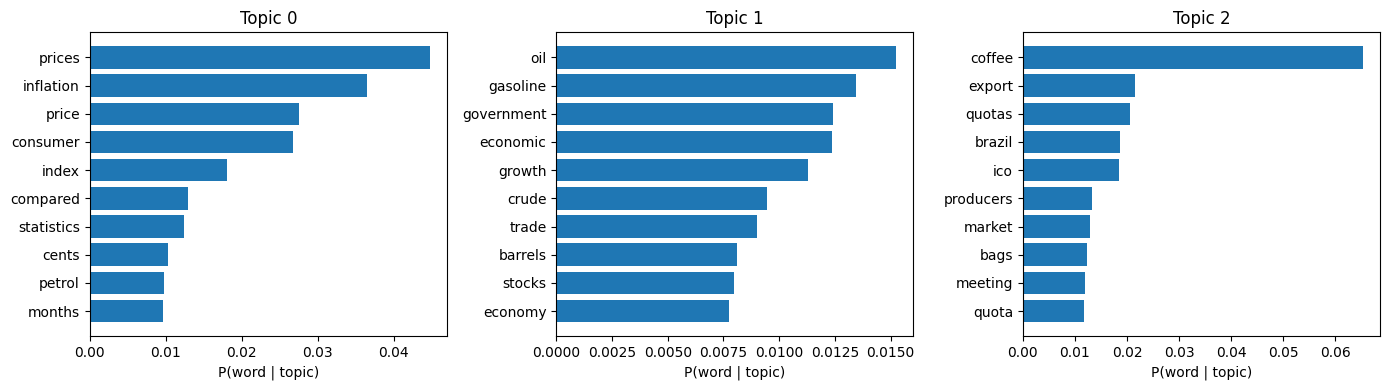

In [17]:
n_top_words = 10

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for k, ax in enumerate(axes):
    top_indices = np.argsort(reuters_topic_word[k])[::-1][:n_top_words]
    ax.barh(reuters_vocabulary[top_indices][::-1], reuters_topic_word[k, top_indices][::-1])
    ax.set_title(f"Topic {k}")
    ax.set_xlabel("P(word | topic)")
plt.tight_layout()
plt.show()

### Documents: mixtures of topics

The three topics are easy to name: one is about consumer prices and inflation ("prices", "inflation", "consumer", "index"), one about oil and the economy in general ("oil", "gasoline", "crude", "growth", "trade"), and one about the coffee market ("coffee", "export", "quotas", "brazil", "ico" for the International Coffee Organization). Note that LDA does not name or order the topics; we interpret them from their words.

Each row of $\hat\Theta$ gives the topic proportions of one article. Below are a few articles from each category.

In [18]:
doc_topic_table = pd.DataFrame(reuters_doc_topic, columns=[f"topic {k}" for k in range(3)])
doc_topic_table["category"] = labels

doc_topic_table.groupby("category").head(3).round(3)

,topic 0,topic 1,topic 2,category
0,0.400,0.594,0.006,gas
1,0.023,0.954,0.023,gas
2,0.006,0.988,0.006,gas
54,0.031,0.967,0.002,cpi
55,0.341,0.385,0.273,cpi
56,0.412,0.584,0.004,cpi
151,0.078,0.638,0.284,coffee
152,0.010,0.485,0.506,coffee
153,0.012,0.010,0.978,coffee


Assigning every article to its most probable topic and cross-tabulating with the Reuters categories shows how well the unsupervised topics match the editors' categories.

In [19]:
doc_topic_table["dominant topic"] = reuters_doc_topic.argmax(axis=1)
pd.crosstab(doc_topic_table["category"], doc_topic_table["dominant topic"])

dominant topic,0,1,2
category,,,
coffee,6,25,108
cpi,70,27,0
gas,14,40,0


Most coffee articles fall into the coffee topic and most CPI articles into the prices topic, although LDA never saw the categories. The match is not perfect, and it does not have to be: the oil-and-economy topic collects articles about the general economic situation from all three categories (e.g. coffee articles about export earnings of producing countries). Topics describe word co-occurrence patterns, not editorial labels.

### The effect of $\alpha$

A small $\alpha$ (`doc_topic_prior`) tells the model that documents should use few topics. We refit with a small and a large value (scikit-learn allows values up to 1) and compare how concentrated the topic proportions are, measured by the share of the largest topic in each document.

alpha = 0.05: mean share of the largest topic = 0.910
alpha = 1.0: mean share of the largest topic = 0.821


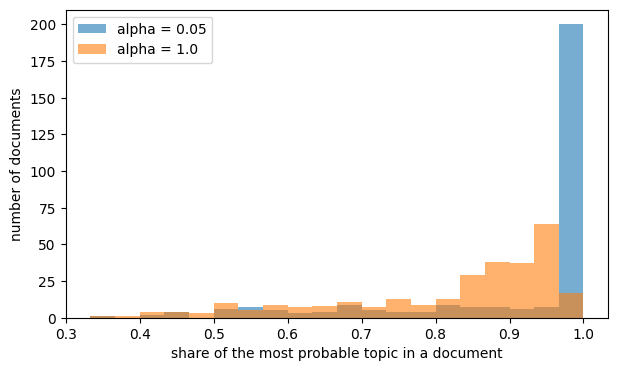

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
for prior in [0.05, 1.0]:
    lda_prior = LatentDirichletAllocation(n_components=3, doc_topic_prior=prior, max_iter=50, random_state=42)
    largest_share = lda_prior.fit_transform(reuters_counts).max(axis=1)
    ax.hist(largest_share, bins=20, range=(1 / 3, 1), alpha=0.6, label=f"alpha = {prior}")
    print(f"alpha = {prior}: mean share of the largest topic = {largest_share.mean():.3f}")
ax.set_xlabel("share of the most probable topic in a document")
ax.set_ylabel("number of documents")
ax.legend()
plt.show()

### Choosing the number of topics

$K$ must be chosen in advance. One numerical guide is the **perplexity**, $\exp(-\text{log-likelihood per word})$: lower values mean that the model assigns higher probability to the words. Perplexity computed on the training documents tends to keep improving as $K$ grows, so it should be computed on held-out documents. In practice, whether the topics are *interpretable* is at least as important as the perplexity.

In [21]:
from sklearn.model_selection import train_test_split

train_counts, test_counts = train_test_split(reuters_counts, test_size=0.25, random_state=42)

perplexities = {}
for n_components in range(2, 8):
    model = LatentDirichletAllocation(n_components=n_components, max_iter=50, random_state=42)
    model.fit(train_counts)
    perplexities[n_components] = model.perplexity(test_counts)

pd.Series(perplexities, name="held-out perplexity").rename_axis("K").round(1)

K
2     814.1
3     884.5
4     994.1
5    1127.4
6    1152.6
7    1237.4
Name: held-out perplexity, dtype: float64

On this small corpus (fewer than 300 articles) the held-out perplexity is lowest for $K = 2$ and grows with $K$: with more topics there are more parameters to estimate from the same few documents. Yet $K = 3$ gives three clearly interpretable topics that match the structure of the corpus. Perplexity is a useful guide, but the final choice of $K$ is usually also made by looking at the topics.

## Summary

| | LSA | LDA |
|---|-----|-----|
| Model | Linear algebra (truncated SVD) | Probabilistic generative model |
| Input | TF-IDF (or counts) | Raw word counts |
| Topic | Direction in word space, entries can be negative | Probability distribution over words |
| Document | Coordinates in topic space | Probability distribution over topics |
| Fitting | SVD (exact, deterministic) | Approximate inference (Gibbs sampling, variational Bayes) |
| Main tuning | Number of components | Number of topics $K$, priors $\alpha$ and $\eta$ |

- The Dirichlet distribution is a distribution over probability vectors. Its concentration $\alpha$ controls whether samples are sparse ($\alpha < 1$) or even ($\alpha > 1$).
- LDA assumes each document is generated by drawing topic proportions $\theta_d \sim \text{Dir}(\alpha)$, then for each word a topic $z_{d,n}$ and a word from that topic's distribution $\beta_{z_{d,n}}$.
- The matrix of word probabilities factorises as $\Theta B$ with non-negative, row-normalised factors, which makes topics and documents easy to interpret.
- The posterior over topics is approximated, e.g. with collapsed Gibbs sampling, whose update combines "how much the document uses the topic" with "how much the topic uses the word".

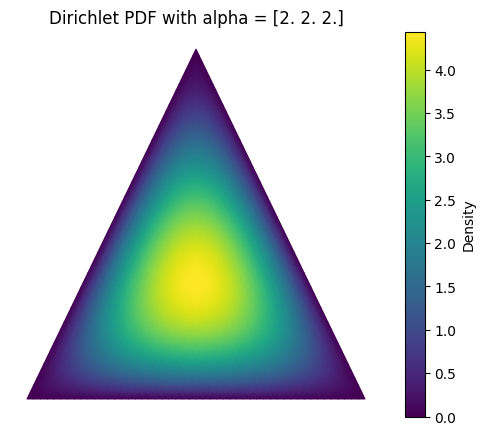

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import dirichlet

# Define parameters alpha for a 3-variable Dirichlet distribution
alpha = np.array([2.0, 2.0, 2.0]) # Try changing to [0.5, 0.5, 0.5] or [5.0, 1.0, 1.0]

# Generate points on the simplex
# (Using a grid over barycentric coordinates)
def draw_dirichlet_triangle(alpha):
    # Setup grid for ternary plot
    n_points = 50
    points = []
    values = []
    
    for i in range(n_points + 1):
        for j in range(n_points + 1 - i):
            k = n_points - i - j
            x = np.array([i, j, k]) / n_points
            # Exclude strict zeros to avoid log/boundary issues if needed, or evaluate PDF directly
            if np.all(x >= 0):
                points.append(x)
                values.append(dirichlet.pdf(x, alpha))
                
    points = np.array(points)
    values = np.array(values)
    
    # Convert barycentric coordinates to Cartesian coordinates for plotting
    # Vertex 1: (0.5, sqrt(3)/2), Vertex 2: (0, 0), Vertex 3: (1, 0)
    v1 = np.array([0.5, np.sqrt(3)/2])
    v2 = np.array([0.0, 0.0])
    v3 = np.array([1.0, 0.0])
    
    cart_coords = points[:, 0, None] * v1 + points[:, 1, None] * v2 + points[:, 2, None] * v3
    
    plt.figure(figsize=(6, 5))
    plt.tripcolor(cart_coords[:, 0], cart_coords[:, 1], values, shading='gouraud', cmap='viridis')
    plt.colorbar(label='Density')
    plt.title(f'Dirichlet PDF with alpha = {alpha}')
    plt.axis('off')
    plt.show()

draw_dirichlet_triangle(alpha)